In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load Mobile Price Classification Dataset
df = pd.read_csv("dataset/train.csv")

print("Dataset Loaded Successfully!")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [6]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18

In [7]:
# Select RAM feature
ram_values = df["ram"].values[:100]

# Normalize RAM values
x = (ram_values - ram_values.mean()) / ram_values.std()

print("Original RAM Values:")
print(ram_values[:10])

print("\nNormalized Values:")
print(x[:10])

Original RAM Values:
[2549 2631 2603 2769 1411 1067 3220  700 1099  513]

Normalized Values:
[ 0.33630022  0.41287216  0.38672564  0.54173713 -0.72636888 -1.0475975
  0.96288279 -1.39030362 -1.01771577 -1.56492499]


In [8]:
# Sigmoid Function
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


# ReLU Function
def relu(x):
    return np.maximum(0, x)


# Tanh Function
def tanh(x):
    return np.tanh(x)


# Softmax Function
def softmax(x):
    exp_x = np.exp(x - np.max(x))
    return exp_x / np.sum(exp_x)


print("All Activation Functions Defined Successfully!")

All Activation Functions Defined Successfully!


In [9]:
# Apply Activation Functions
sigmoid_output = sigmoid(x)
relu_output = relu(x)
tanh_output = tanh(x)
softmax_output = softmax(x)

print("Sigmoid Output:")
print(sigmoid_output[:10])

print("\nReLU Output:")
print(relu_output[:10])

print("\nTanh Output:")
print(tanh_output[:10])

print("\nSoftmax Output:")
print(softmax_output[:10])

print("\nSum of Softmax Probabilities:")
print(np.sum(softmax_output))

Sigmoid Output:
[0.58329152 0.60177637 0.59549422 0.63221643 0.32599206 0.25968671
 0.72369862 0.19935929 0.26547258 0.17294108]

ReLU Output:
[0.33630022 0.41287216 0.38672564 0.54173713 0.         0.
 0.96288279 0.         0.         0.        ]

Tanh Output:
[ 0.32417039  0.39090867  0.36853401  0.49430178 -0.62083884 -0.78087056
  0.74555999 -0.88323767 -0.76893452 -0.91621474]

Softmax Output:
[0.00892545 0.00963574 0.00938706 0.010961   0.00308403 0.00223672
 0.01670135 0.00158773 0.00230456 0.00133333]

Sum of Softmax Probabilities:
1.0000000000000002


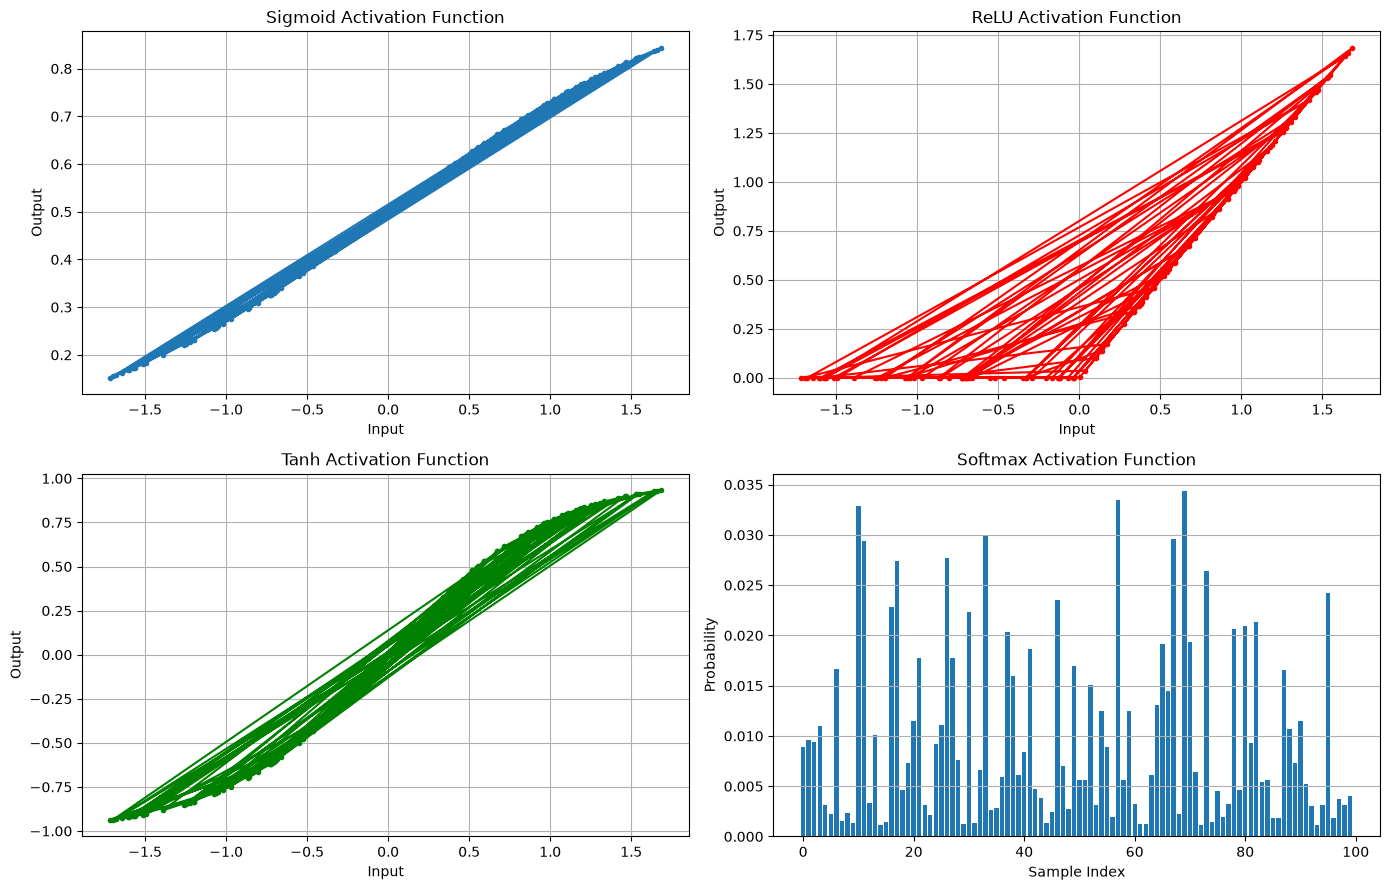

In [10]:
plt.figure(figsize=(14, 9))

# Sigmoid
plt.subplot(2, 2, 1)
plt.plot(x, sigmoid_output, marker='o', markersize=3)
plt.title("Sigmoid Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)

# ReLU
plt.subplot(2, 2, 2)
plt.plot(x, relu_output, color='red', marker='o', markersize=3)
plt.title("ReLU Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)

# Tanh
plt.subplot(2, 2, 3)
plt.plot(x, tanh_output, color='green', marker='o', markersize=3)
plt.title("Tanh Activation Function")
plt.xlabel("Input")
plt.ylabel("Output")
plt.grid(True)

# Softmax
plt.subplot(2, 2, 4)
plt.bar(range(len(softmax_output)), softmax_output)
plt.title("Softmax Activation Function")
plt.xlabel("Sample Index")
plt.ylabel("Probability")
plt.grid(axis='y')

plt.tight_layout()
plt.show()

In [11]:
comparison = pd.DataFrame({
    "RAM Input": x[:10],
    "Sigmoid": sigmoid_output[:10],
    "ReLU": relu_output[:10],
    "Tanh": tanh_output[:10],
    "Softmax": softmax_output[:10]
})

display(comparison)

,RAM Input,Sigmoid,ReLU,Tanh,Softmax
0,0.336300,0.583292,0.336300,0.324170,0.008925
1,0.412872,0.601776,0.412872,0.390909,0.009636
2,0.386726,0.595494,0.386726,0.368534,0.009387
3,0.541737,0.632216,0.541737,0.494302,0.010961
4,-0.726369,0.325992,0.000000,-0.620839,0.003084
5,-1.047598,0.259687,0.000000,-0.780871,0.002237
6,0.962883,0.723699,0.962883,0.745560,0.016701
7,-1.390304,0.199359,0.000000,-0.883238,0.001588
8,-1.017716,0.265473,0.000000,-0.768935,0.002305
9,-1.564925,0.172941,0.000000,-0.916215,0.001333


In [12]:
# Check Softmax Probability

print("Total Softmax Probability:",
      np.sum(softmax_output))

print("\nMinimum Sigmoid:", np.min(sigmoid_output))
print("Maximum Sigmoid:", np.max(sigmoid_output))

print("\nMinimum ReLU:", np.min(relu_output))
print("Maximum ReLU:", np.max(relu_output))

print("\nMinimum Tanh:", np.min(tanh_output))
print("Maximum Tanh:", np.max(tanh_output))

Total Softmax Probability: 1.0000000000000002

Minimum Sigmoid: 0.15212007305522895
Maximum Sigmoid: 0.8435276524905441

Minimum ReLU: 0.0
Maximum ReLU: 1.6847133833464822

Minimum Tanh: -0.9376300766513053
Maximum Tanh: 0.9334705238862359
